In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_customer = pd.read_csv(
    "../output/customer_profile.csv",
    dtype={"Customer ID": "string"}
)

print("- KIỂM TRA DỮ LIỆU -")
print("Kích thước:", df_customer.shape)
print("Số khách hàng:", df_customer["Customer ID"].nunique())
print("Giá trị thiếu:")
print(df_customer.isna().sum().to_string())

print("\nSố khách hàng theo cụm:")
print(
    df_customer["Cluster"]
    .value_counts()
    .sort_index()
    .to_string()
)

- KIỂM TRA DỮ LIỆU -
Kích thước: (5878, 5)
Số khách hàng: 5878
Giá trị thiếu:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
Cluster        0

Số khách hàng theo cụm:
Cluster
0    1839
1    1675
2    2364


In [2]:
recency_by_cluster = (
    df_customer.groupby("Cluster")["Recency"]
    .describe(percentiles=[0.25, 0.5, 0.75])
)

print("- RECENCY THEO CLUSTER -")
print(recency_by_cluster.round(2).to_string())

print("\n- KHÁCH HÀNG THEO NGƯỠNG RECENCY -")

thresholds = [90, 180, 365]

for days in thresholds:
    count = (df_customer["Recency"] > days).sum()
    percent = count / len(df_customer) * 100

    print(
        f"Recency > {days} ngày: "
        f"{count} khách hàng ({percent:.2f}%)"
    )

- RECENCY THEO CLUSTER -
          count    mean     std    min    25%    50%    75%    max
Cluster                                                           
0        1839.0  473.59  126.88  177.0  386.0  438.0  575.5  739.0
1        1675.0   57.79   85.42    1.0   10.0   26.0   67.0  633.0
2        2364.0   92.57   84.80    1.0   25.0   62.0  149.0  386.0

- KHÁCH HÀNG THEO NGƯỠNG RECENCY -
Recency > 90 ngày: 2989 khách hàng (50.85%)
Recency > 180 ngày: 2401 khách hàng (40.85%)
Recency > 365 ngày: 1614 khách hàng (27.46%)


In [4]:
df_transactions = pd.read_csv(
    "../output/online_retail_clean_backup.csv",
    usecols=["Customer ID", "Invoice", "InvoiceDate"],
    dtype={
        "Customer ID": "string",
        "Invoice": "string"
    },
    parse_dates=["InvoiceDate"]
)

# Mỗi hóa đơn tương ứng một lần mua
invoice_dates = (
    df_transactions
    .groupby(["Customer ID", "Invoice"], as_index=False)
    .agg(PurchaseDate=("InvoiceDate", "min"))
)

invoice_dates = invoice_dates.sort_values(
    ["Customer ID", "PurchaseDate", "Invoice"]
)

# Khoảng cách giữa hai lần mua liên tiếp, tính theo ngày
invoice_dates["PurchaseGap"] = (
    invoice_dates.groupby("Customer ID")["PurchaseDate"]
    .diff()
    .dt.total_seconds() / 86400
)

purchase_gaps = invoice_dates["PurchaseGap"].dropna()

print("- KHOẢNG CÁCH GIỮA CÁC LẦN MUA -")
print(
    purchase_gaps.describe(
        percentiles=[0.25, 0.5, 0.75]
    ).round(2).to_string()
)

print("\nSố khoảng cách quan sát:", len(purchase_gaps))
print(
    "Số khách hàng có từ 2 hóa đơn:",
    invoice_dates.groupby("Customer ID")
    .size()
    .ge(2)
    .sum()
)

- KHOẢNG CÁCH GIỮA CÁC LẦN MUA -
count    31091.00
mean        51.69
std         75.79
min          0.00
25%          6.98
50%         24.74
75%         61.81
max        714.15

Số khoảng cách quan sát: 31091
Số khách hàng có từ 2 hóa đơn: 4255


In [6]:
# Gán mức Inactivity Risk theo Recency
conditions = [
    df_customer["Recency"] <= 90,
    (df_customer["Recency"] > 90) &
    (df_customer["Recency"] <= 180),
    df_customer["Recency"] > 180
]

risk_labels = ["Low Risk", "Medium Risk", "High Risk"]

df_customer["Inactivity_Risk"] = np.select(
    conditions,
    risk_labels,
    default="Unknown"
)

risk_summary = (
    df_customer.groupby("Inactivity_Risk")
    .agg(
        Customers=("Customer ID", "count"),
        Monetary_Total=("Monetary", "sum"),
        Recency_Median=("Recency", "median"),
        Frequency_Median=("Frequency", "median"),
        Monetary_Median=("Monetary", "median")
    )
    .reindex(risk_labels)
)

risk_summary["Customer_Percent"] = (
    risk_summary["Customers"] / len(df_customer) * 100
)

risk_summary["Monetary_Percent"] = (
    risk_summary["Monetary_Total"]
    / df_customer["Monetary"].sum() * 100
)

print("- PHÂN BỐ MỨC ĐỘ RỦI RO -")
print(risk_summary.round(2).to_string())

print("\nKiểm tra:")
print("Tổng khách hàng:", risk_summary["Customers"].sum())
print("Nhãn Unknown:", (df_customer["Inactivity_Risk"] == "Unknown").sum())

- PHÂN BỐ MỨC ĐỘ RỦI RO -
                 Customers  Monetary_Total  Recency_Median  Frequency_Median  Monetary_Median  Customer_Percent  Monetary_Percent
Inactivity_Risk                                                                                                                  
Low Risk              2889     13983420.61            26.0               5.0          1660.29             49.15             80.48
Medium Risk            588      1054571.21           131.0               4.0           999.92             10.00              6.07
High Risk             2401      2336812.44           408.0               2.0           407.94             40.85             13.45

Kiểm tra:
Tổng khách hàng: 5878
Nhãn Unknown: 0


In [7]:
risk_cluster = pd.crosstab(
    df_customer["Cluster"],
    df_customer["Inactivity_Risk"]
).reindex(
    columns=risk_labels,
    fill_value=0
)

risk_cluster_percent = pd.crosstab(
    df_customer["Cluster"],
    df_customer["Inactivity_Risk"],
    normalize="index"
).reindex(
    columns=risk_labels,
    fill_value=0
) * 100

print("- SỐ KHÁCH HÀNG THEO CLUSTER VÀ RISK -")
print(risk_cluster.to_string())

print("\n- TỶ LỆ RỦI RO TRONG TỪNG CLUSTER (%) -")
print(risk_cluster_percent.round(2).to_string())

- SỐ KHÁCH HÀNG THEO CLUSTER VÀ RISK -
Inactivity_Risk  Low Risk  Medium Risk  High Risk
Cluster                                          
0                       0            1       1838
1                    1379          164        132
2                    1510          423        431

- TỶ LỆ RỦI RO TRONG TỪNG CLUSTER (%) -
Inactivity_Risk  Low Risk  Medium Risk  High Risk
Cluster                                          
0                    0.00         0.05      99.95
1                   82.33         9.79       7.88
2                   63.87        17.89      18.23


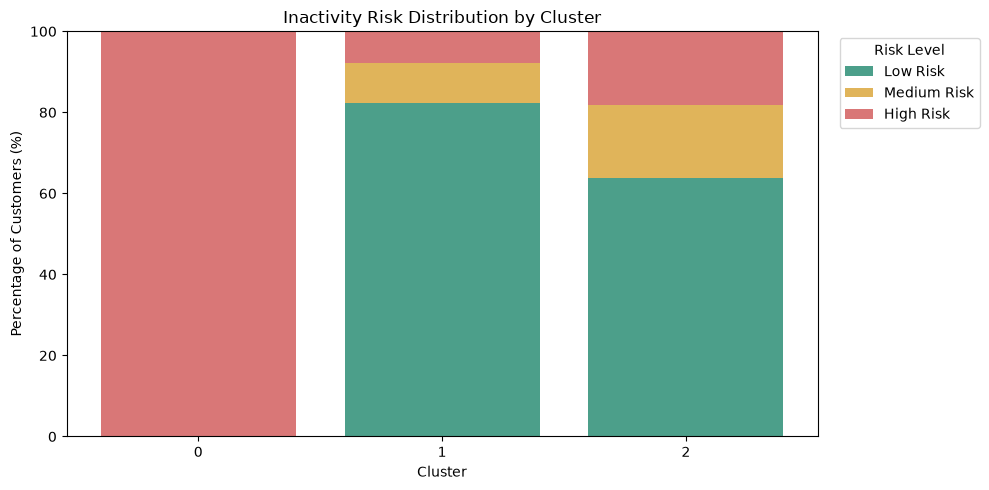

In [8]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5))

clusters = risk_cluster_percent.index.astype(str)
bottom = np.zeros(len(clusters))

colors = ["#4C9F8A", "#E0B45A", "#D97777"]

for risk, color in zip(risk_labels, colors):
    values = risk_cluster_percent[risk].values

    ax.bar(
        clusters,
        values,
        bottom=bottom,
        label=risk,
        color=color
    )

    bottom += values

ax.set_title("Inactivity Risk Distribution by Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Percentage of Customers (%)")
ax.set_ylim(0, 100)
ax.legend(title="Risk Level", bbox_to_anchor=(1.02, 1),
          loc="upper left")

plt.tight_layout()

plt.savefig(
    "../output/inactivity_risk_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
from pathlib import Path

output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "customer_analytics_final.csv"

df_customer.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu:", output_path.resolve())
print("Kích thước:", df_customer.shape)
print("Giá trị thiếu:", df_customer.isna().sum().sum())

print("\nCác cột dữ liệu:")
print(df_customer.columns.tolist())

print("\n10 khách hàng đầu tiên:")
print(df_customer.head(10).to_string(index=False))

Đã lưu: C:\Users\Admin\Desktop\Học tập\Thực tập & tốt nghiệp\analytics\output\customer_analytics_final.csv
Kích thước: (5878, 6)
Giá trị thiếu: 0

Các cột dữ liệu:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Cluster', 'Inactivity_Risk']

10 khách hàng đầu tiên:
Customer ID  Recency  Frequency  Monetary  Cluster Inactivity_Risk
      12346      326         12  77556.46        1       High Risk
      12347        3          8   4921.53        1        Low Risk
      12348       76          5   2019.40        2        Low Risk
      12349       19          4   4428.69        1        Low Risk
      12350      311          1    334.40        0       High Risk
      12351      376          1    300.93        0       High Risk
      12352       37         10   2849.84        1        Low Risk
      12353      205          2    406.76        2       High Risk
      12354      233          1   1079.40        2       High Risk
      12355      215          2    947.61        2       Hi

In [10]:
high_risk_cluster_1 = df_customer[
    (df_customer["Cluster"] == 1) &
    (df_customer["Inactivity_Risk"] == "High Risk")
]

print("Số khách hàng:", len(high_risk_cluster_1))
print(
    "Tổng Monetary (GBP):",
    round(high_risk_cluster_1["Monetary"].sum(), 2)
)
print(
    "Monetary trung vị (GBP):",
    round(high_risk_cluster_1["Monetary"].median(), 2)
)

Số khách hàng: 132
Tổng Monetary (GBP): 913962.04
Monetary trung vị (GBP): 3424.98
